# Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading CSV's

In [ ]:
municipalCaseParties = pd.read_csv('municipal_case_parties.csv')
popInfo = pd.read_csv('municipal_population_2000_2024.csv')

In [ ]:
#GATEWAY CITIES TO REFERENCE BACK TO
gateway_cities = [
    'Attleboro', 'Barnstable', 'Brockton', 'Chelsea', 'Chicopee',
    'Everett', 'Fall River', 'Fitchburg', 'Haverhill', 'Holyoke',
    'Lawrence', 'Leominster', 'Lowell', 'Lynn', 'Malden',
    'Methuen', 'New Bedford', 'Peabody', 'Pittsfield', 'Quincy',
    'Revere', 'Salem', 'Springfield', 'Taunton', 'Westfield', 'Worcester'
]

#Cleaning

In [ ]:
# Ensure file_date is datetime and extract year for municipalCaseParties if not already done
municipalCaseParties['file_date'] = pd.to_datetime(municipalCaseParties['file_date'], errors='coerce')
municipalCaseParties['year'] = municipalCaseParties['file_date'].dt.year

# Filter municipalCaseParties for years between 2006 and 2024
municipalCaseParties = municipalCaseParties[(municipalCaseParties['year'] >= 2006) & (municipalCaseParties['year'] <= 2024)]

# Filter popInfo for years between 2006 and 2024
popInfo = popInfo[(popInfo['year'] >= 2006) & (popInfo['year'] <= 2024)]


In [ ]:
municipalCaseParties = municipalCaseParties[municipalCaseParties['party_type'].astype(str).str.lower().str.contains('defendant', na=False)]

In [ ]:
# Show unique values in the case type column
# Let's inspect columns first to find the exact case type column name if it contains spaces or underscores
case_type_col = [col for col in municipalCaseParties.columns if 'case' in col.lower() and 'type' in col.lower()]
if case_type_col:
    print(f"Unique values in '{case_type_col[0]}':")
    print(municipalCaseParties[case_type_col[0]].unique())
else:
    # Fallback to standard column lookup
    print(municipalCaseParties['case_type'].unique())

Unique values in 'case_type':
['Administrative Civil Actions' 'Civil' 'Small Claims'
 'Actions Involving the State/Municipality' 'Permit Session'
 'Miscellaneous' 'Real Property' 'Housing Court Civil'
 'Equitable Remedies' 'Torts' 'Contract / Business Cases' 'Other Court'
 'Subsequent' 'Tax Lien' 'Servicemembers'
 'Civil Actions with Incarcerated Party' 'Equity Complaint'
 'Business Litigation' 'Parentage in Equity' 'Summary Process' 'Criminal'
 'Housing Court Summary Process' 'Housing Court Small Claims'
 'Supplementary Process']


In [ ]:
category_mapping = {
    'Housing Court Civil': 'Housing',
    'Housing Court Small Claims': 'Housing',
    'Housing Court Summary Process': 'Housing',
    'Summary Process': 'Housing',
    'Civil': 'Civil',
    'Administrative Civil Actions': 'Civil',
    'Miscellaneous Civil Actions': 'Civil',
    'Civil Actions with Incarcerated Party': 'Civil',
    'Small Claims': 'Small Claims',
    'Actions Involving the State/Municipality': 'State/Municipality',
    'Permit Session': 'Permit',
    'Real Property': 'Real Property',
    'Equitable Remedies': 'Equity/Remedies',
    'Equity Petition': 'Equity/Remedies',
    'Equity Complaint': 'Equity/Remedies',
    'Equity - Partition': 'Equity/Remedies',
    'Parentage in Equity': 'Equity/Remedies',
    'Contract / Business Cases': 'Business/Contract',
    'Business Litigation': 'Business/Contract',
    'Torts': 'Torts',
    'Tax Lien': 'Tax/Financial',
    'Servicemembers': 'Special Sessions',
    'Supplementary Process': 'Civil',
    'Subsequent': 'Other',
    'Other Court': 'Other',
    'Miscellaneous': 'Other',
    'Administrative Appeals': 'Administrative',
    'Criminal': 'Criminal',
    'Criminal Complaint': 'Criminal',
    'Indictment': 'Criminal',
    'Estates and Administration': 'Probate/Estate',
    'Probate Other': 'Probate/Estate'
}

municipalCaseParties['case_category'] = municipalCaseParties['case_type'].map(category_mapping).fillna('Other')

display(municipalCaseParties[['case_type', 'case_category']].drop_duplicates().head(15))
print("\nCase category value counts:")
display(municipalCaseParties['case_category'].value_counts())

,case_type,case_category
4,Administrative Civil Actions,Civil
9,Civil,Civil
12,Small Claims,Small Claims
26,Actions Involving the State/Municipality,State/Municipality
27,Permit Session,Permit
34,Miscellaneous,Other
126,Real Property,Real Property
196,Housing Court Civil,Housing
280,Equitable Remedies,Equity/Remedies
634,Torts,Torts



Case category value counts:


,count
case_category,
State/Municipality,6173
Civil,5922
Real Property,3391
Torts,2315
Other,2281
Equity/Remedies,1682
Tax/Financial,1395
Small Claims,1033
Business/Contract,631


# Plotting

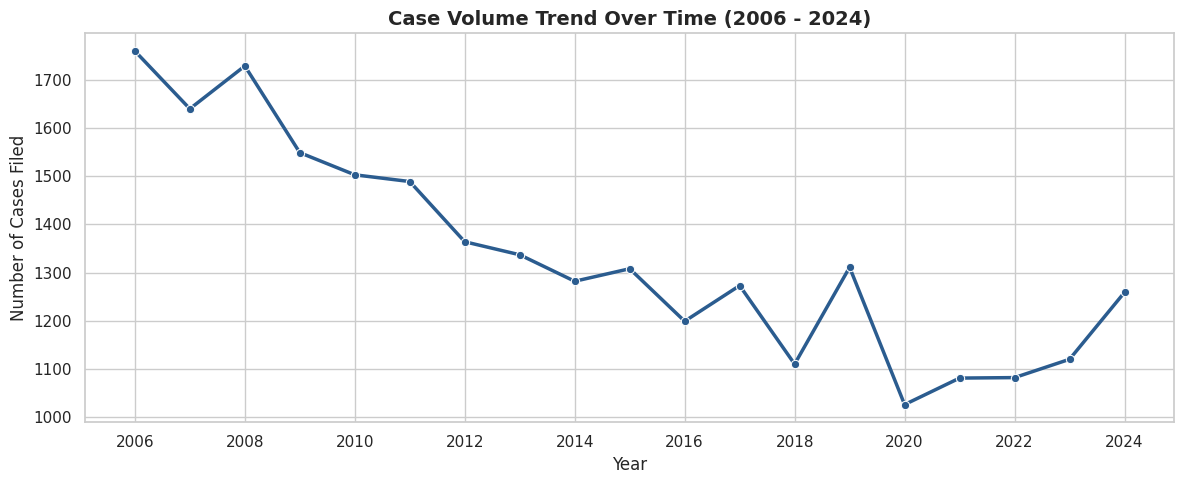

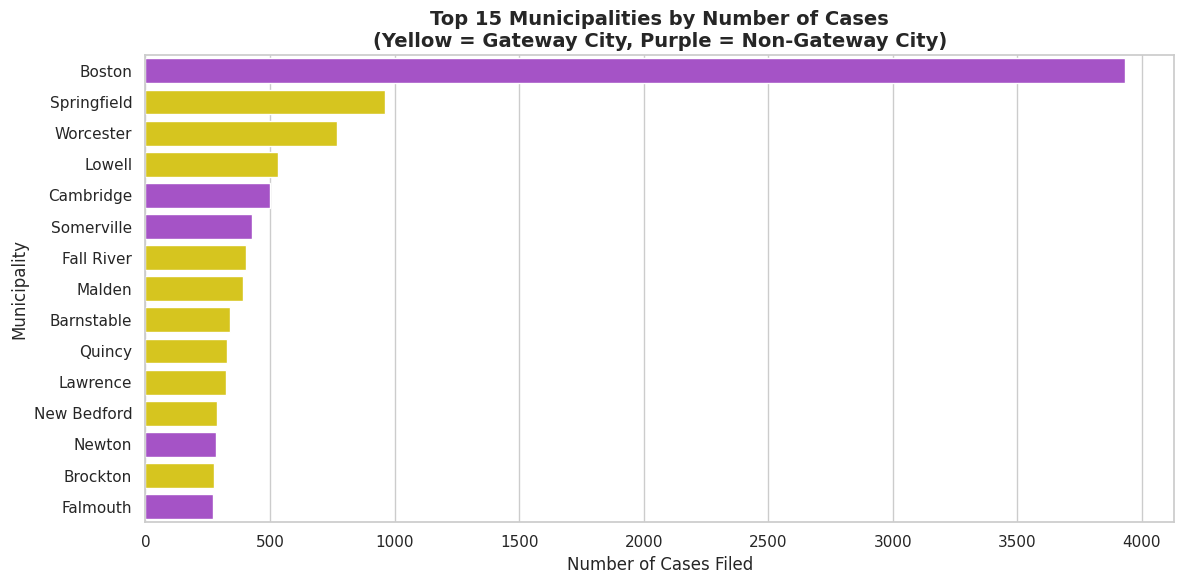

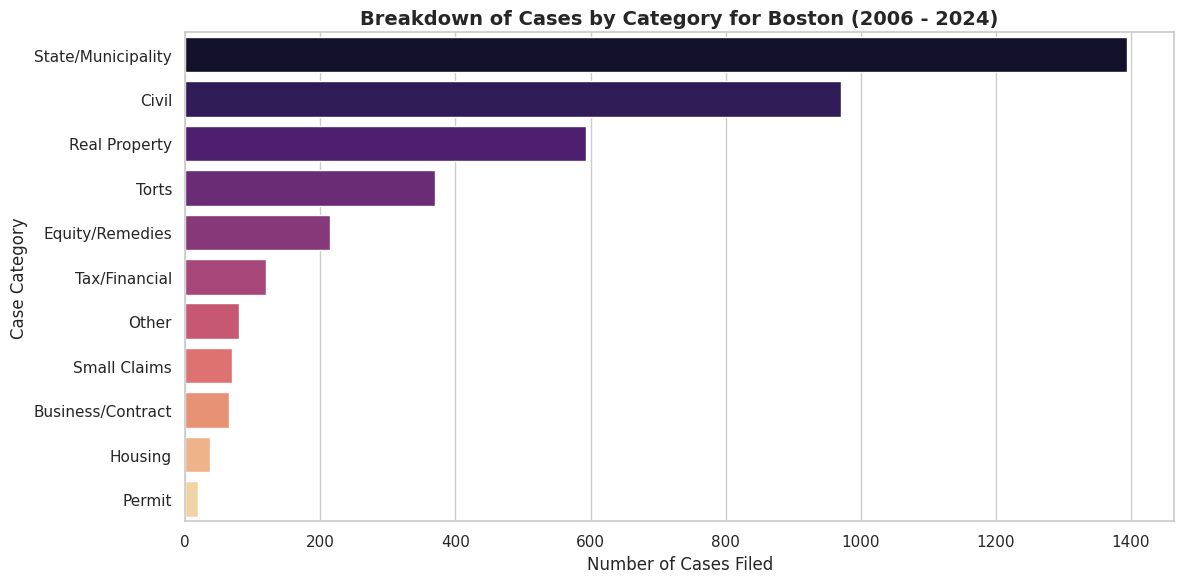

In [ ]:
# Set plotting style
sns.set_theme(style="whitegrid")

# Drop any rows with invalid/null years for clean time trends
time_df = municipalCaseParties.dropna(subset=['year'])
time_df = time_df[(time_df['year'] >= 2006) & (time_df['year'] <= 2024)]

# Plot 1: Trends Over Time (Annual Case Volume)
plt.figure(figsize=(12, 5))
yearly_counts = time_df['year'].value_counts().sort_index()
sns.lineplot(x=yearly_counts.index, y=yearly_counts.values, marker='o', color='#2b5c8f', linewidth=2.5)
plt.title('Case Volume Trend Over Time (2006 - 2024)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Cases Filed', fontsize=12)
plt.xticks(np.arange(2006, 2025, 2))
plt.tight_layout()
plt.show()

# Plot 2: Top 15 Municipalities by Case Count with Gateway Cities Color-Coding
plt.figure(figsize=(12, 6))
top_municipalities = municipalCaseParties['municipality'].value_counts().head(15)

# Map colors dynamically: Gateway Cities are '#F5DE00', others are '#AD40D9'
colors = [
    '#F5DE00' if m.strip().title() in [g.title() for g in gateway_cities] else '#AD40D9'
    for m in top_municipalities.index
]

sns.barplot(
    x=top_municipalities.values,
    y=top_municipalities.index,
    hue=top_municipalities.index,
    palette=colors,
    legend=False
)
plt.title('Top 15 Municipalities by Number of Cases\n(Yellow = Gateway City, Purple = Non-Gateway City)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Cases Filed', fontsize=12)
plt.ylabel('Municipality', fontsize=12)
plt.tight_layout()
plt.show()

# Plot 3: Breakdown of Case Types (Case Categories) for Boston
plt.figure(figsize=(12, 6))
boston_cases = municipalCaseParties[municipalCaseParties['municipality'].astype(str).str.lower() == 'boston']
boston_category_counts = boston_cases['case_category'].value_counts()

sns.barplot(x=boston_category_counts.values, y=boston_category_counts.index, hue=boston_category_counts.index, palette='magma', legend=False)
plt.title('Breakdown of Cases by Category for Boston (2006 - 2024)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Cases Filed', fontsize=12)
plt.ylabel('Case Category', fontsize=12)
plt.tight_layout()
plt.show()

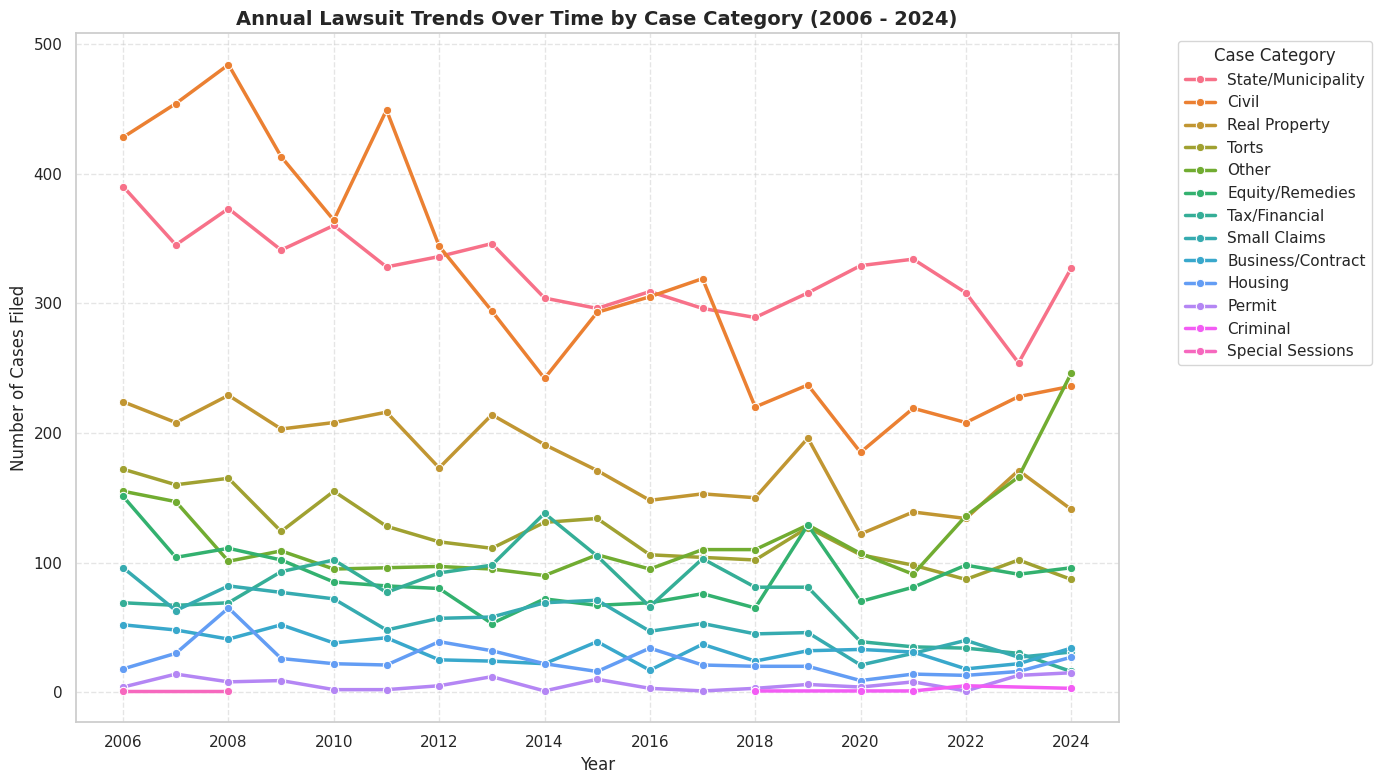

In [ ]:
# Group the raw data by case category and year
category_trends = municipalCaseParties.groupby(['case_category', 'year']).size().reset_index(name='case_count')

# Sort categories by total volume to show the most prominent ones in the legend
top_categories = municipalCaseParties['case_category'].value_counts().index

plt.figure(figsize=(14, 8))
sns.lineplot(
    data=category_trends,
    x='year',
    y='case_count',
    hue='case_category',
    hue_order=top_categories,
    marker='o',
    linewidth=2.5
)

plt.title('Annual Lawsuit Trends Over Time by Case Category (2006 - 2024)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Cases Filed', fontsize=12)
plt.xticks(np.arange(2006, 2025, 2))
plt.legend(title='Case Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Per 10,000 Residents

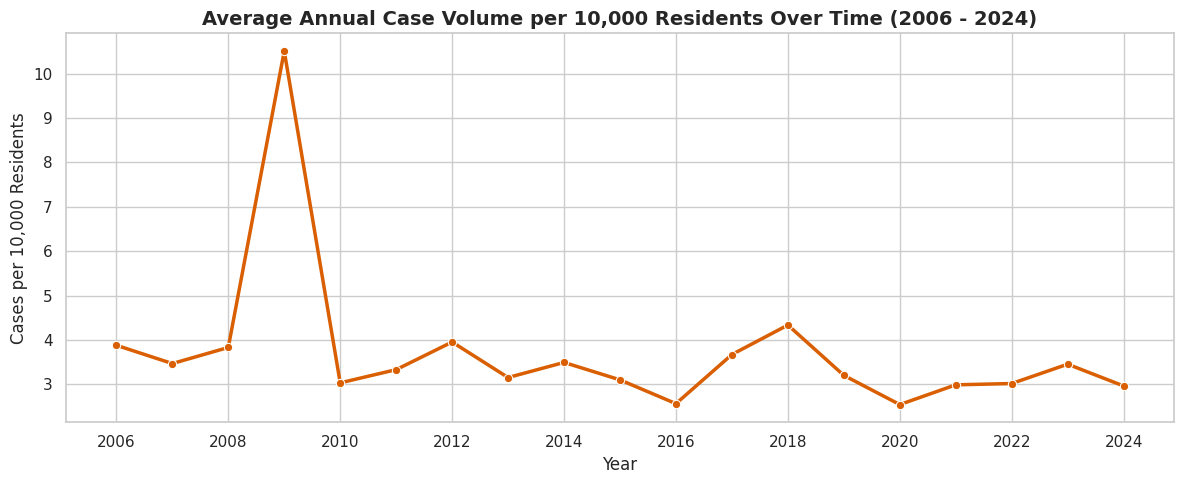

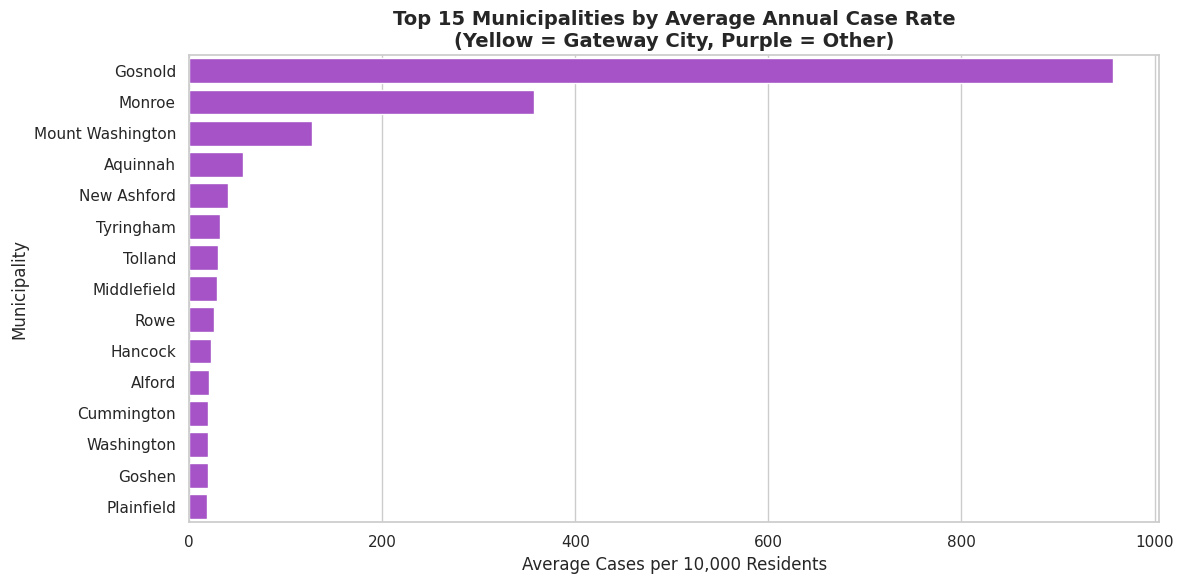

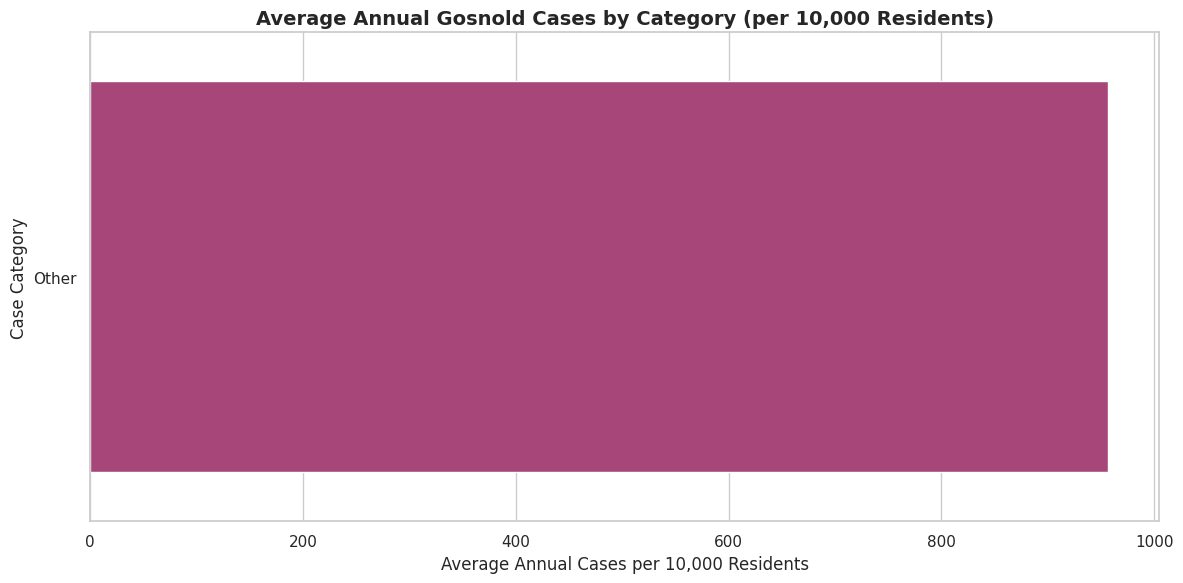

In [ ]:
# Ensure clean, lowercase matching keys for municipalities
municipalCaseParties['muni_key'] = municipalCaseParties['municipality'].astype(str).str.strip().str.lower()
popInfo['muni_key'] = popInfo['municipality'].astype(str).str.strip().str.lower()

# 1. Group case counts by municipality and year
yearly_muni_cases = municipalCaseParties.groupby(['muni_key', 'year']).size().reset_index(name='case_count')

# 2. Merge with population info to get matching population for each year
normalized_df = pd.merge(
    yearly_muni_cases,
    popInfo[['muni_key', 'year', 'population', 'municipality']],
    on=['muni_key', 'year'],
    how='inner'
)

# 3. Calculate cases per 10,000 residents
normalized_df['cases_per_10k'] = (normalized_df['case_count'] / normalized_df['population']) * 10000

# --- Plot 1: Trend Over Time (Average Case Rate across all municipalities) ---
plt.figure(figsize=(12, 5))
yearly_rate = normalized_df.groupby('year')['cases_per_10k'].mean()
sns.lineplot(x=yearly_rate.index, y=yearly_rate.values, marker='o', color='#d95f02', linewidth=2.5)
plt.title('Average Annual Case Volume per 10,000 Residents Over Time (2006 - 2024)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Cases per 10,000 Residents', fontsize=12)
plt.xticks(np.arange(2006, 2025, 2))
plt.tight_layout()
plt.show()

# --- Plot 2: Top 15 Municipalities by Average Case Rate with Gateway Cities Color-Coding ---
plt.figure(figsize=(12, 6))
muni_avg_rate = normalized_df.groupby('municipality')['cases_per_10k'].mean().sort_values(ascending=False).head(15)

# Map colors dynamically: Gateway Cities are '#F5DE00', others are '#AD40D9'
colors = [
    '#F5DE00' if m.strip().title() in [g.title() for g in gateway_cities] else '#AD40D9'
    for m in muni_avg_rate.index
]

sns.barplot(
    x=muni_avg_rate.values,
    y=muni_avg_rate.index,
    hue=muni_avg_rate.index,
    palette=colors,
    legend=False
)
plt.title('Top 15 Municipalities by Average Annual Case Rate\n(Yellow = Gateway City, Purple = Other)', fontsize=14, fontweight='bold')
plt.xlabel('Average Cases per 10,000 Residents', fontsize=12)
plt.ylabel('Municipality', fontsize=12)
plt.tight_layout()
plt.show()

# --- Plot 3: Gosnold Case Category Breakdown Normalized (per 10,000 Residents) ---
# Get Gosnold's annual population
Gosnold_pop = popInfo[popInfo['muni_key'] == 'gosnold'].groupby('year')['population'].first().reset_index()

# Group Gosnold cases by category and year
Gosnold_cat_yearly = municipalCaseParties[municipalCaseParties['muni_key'] == 'gosnold'].groupby(['case_category', 'year']).size().reset_index(name='case_count')

# Merge with Boston population
Gosnold_normalized = pd.merge(Gosnold_cat_yearly, Gosnold_pop, on='year', how='inner')
Gosnold_normalized['cases_per_10k'] = (Gosnold_normalized['case_count'] / Gosnold_normalized['population']) * 10000

# Find the average annual rate per category for Gosnold
Gosnold_cat_rate = Gosnold_normalized.groupby('case_category')['cases_per_10k'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=Gosnold_cat_rate.values, y=Gosnold_cat_rate.index, hue=Gosnold_cat_rate.index, palette='magma', legend=False)
plt.title('Average Annual Gosnold Cases by Category (per 10,000 Residents)', fontsize=14, fontweight='bold')
plt.xlabel('Average Annual Cases per 10,000 Residents', fontsize=12)
plt.ylabel('Case Category', fontsize=12)
plt.tight_layout()
plt.show()

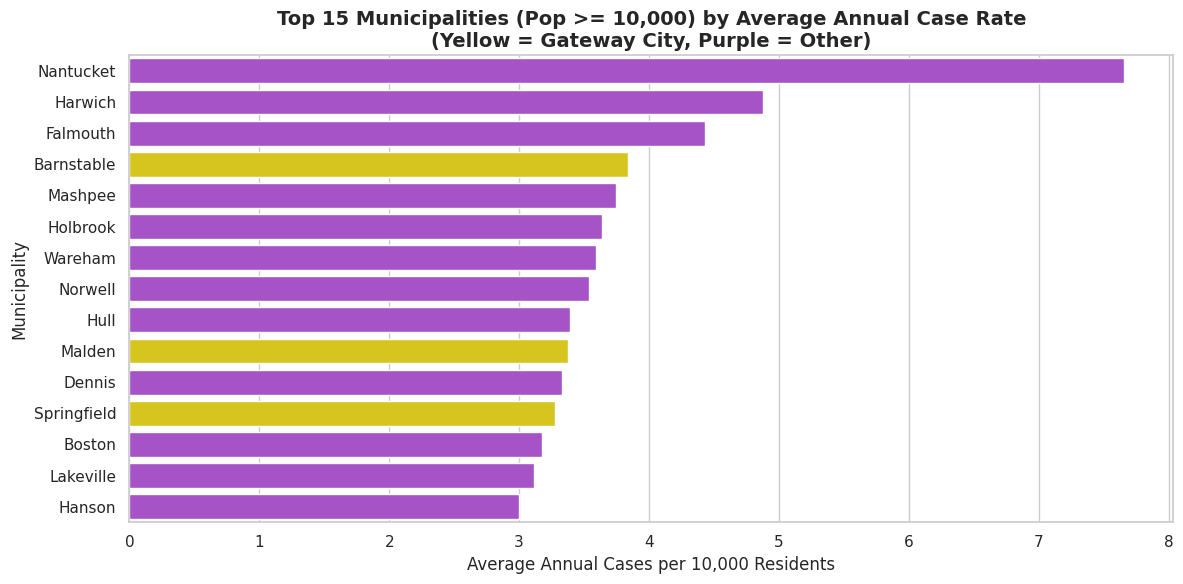

In [ ]:
# Calculate overall average annual cases and population per municipality
muni_stats = normalized_df.groupby('municipality').agg(
    avg_annual_cases=('case_count', 'mean'),
    avg_population=('population', 'mean')
).reset_index()

# Apply the minimum population threshold (population >= 10,000)
threshold = 10000
filtered_muni_stats = muni_stats[muni_stats['avg_population'] >= threshold].copy()
filtered_muni_stats['cases_per_10k_filtered'] = (filtered_muni_stats['avg_annual_cases'] / filtered_muni_stats['avg_population']) * 10000

# Identify top 15 municipalities
top_filtered = filtered_muni_stats.sort_values(by='cases_per_10k_filtered', ascending=False).head(15)

# Plot: Top 15 Municipalities (Filtered >= 10k Pop) with Gateway Cities Color-Coding
plt.figure(figsize=(12, 6))

# Map colors dynamically: Gateway Cities are '#F5DE00', others are '#AD40D9'
colors = [
    '#F5DE00' if m.strip().title() in [g.title() for g in gateway_cities] else '#AD40D9'
    for m in top_filtered['municipality']
]

sns.barplot(
    x='cases_per_10k_filtered',
    y='municipality',
    data=top_filtered,
    hue='municipality',
    palette=colors,
    legend=False
)

plt.title('Top 15 Municipalities (Pop >= 10,000) by Average Annual Case Rate\n(Yellow = Gateway City, Purple = Other)', fontsize=14, fontweight='bold')
plt.xlabel('Average Annual Cases per 10,000 Residents', fontsize=12)
plt.ylabel('Municipality', fontsize=12)
plt.tight_layout()
plt.show()

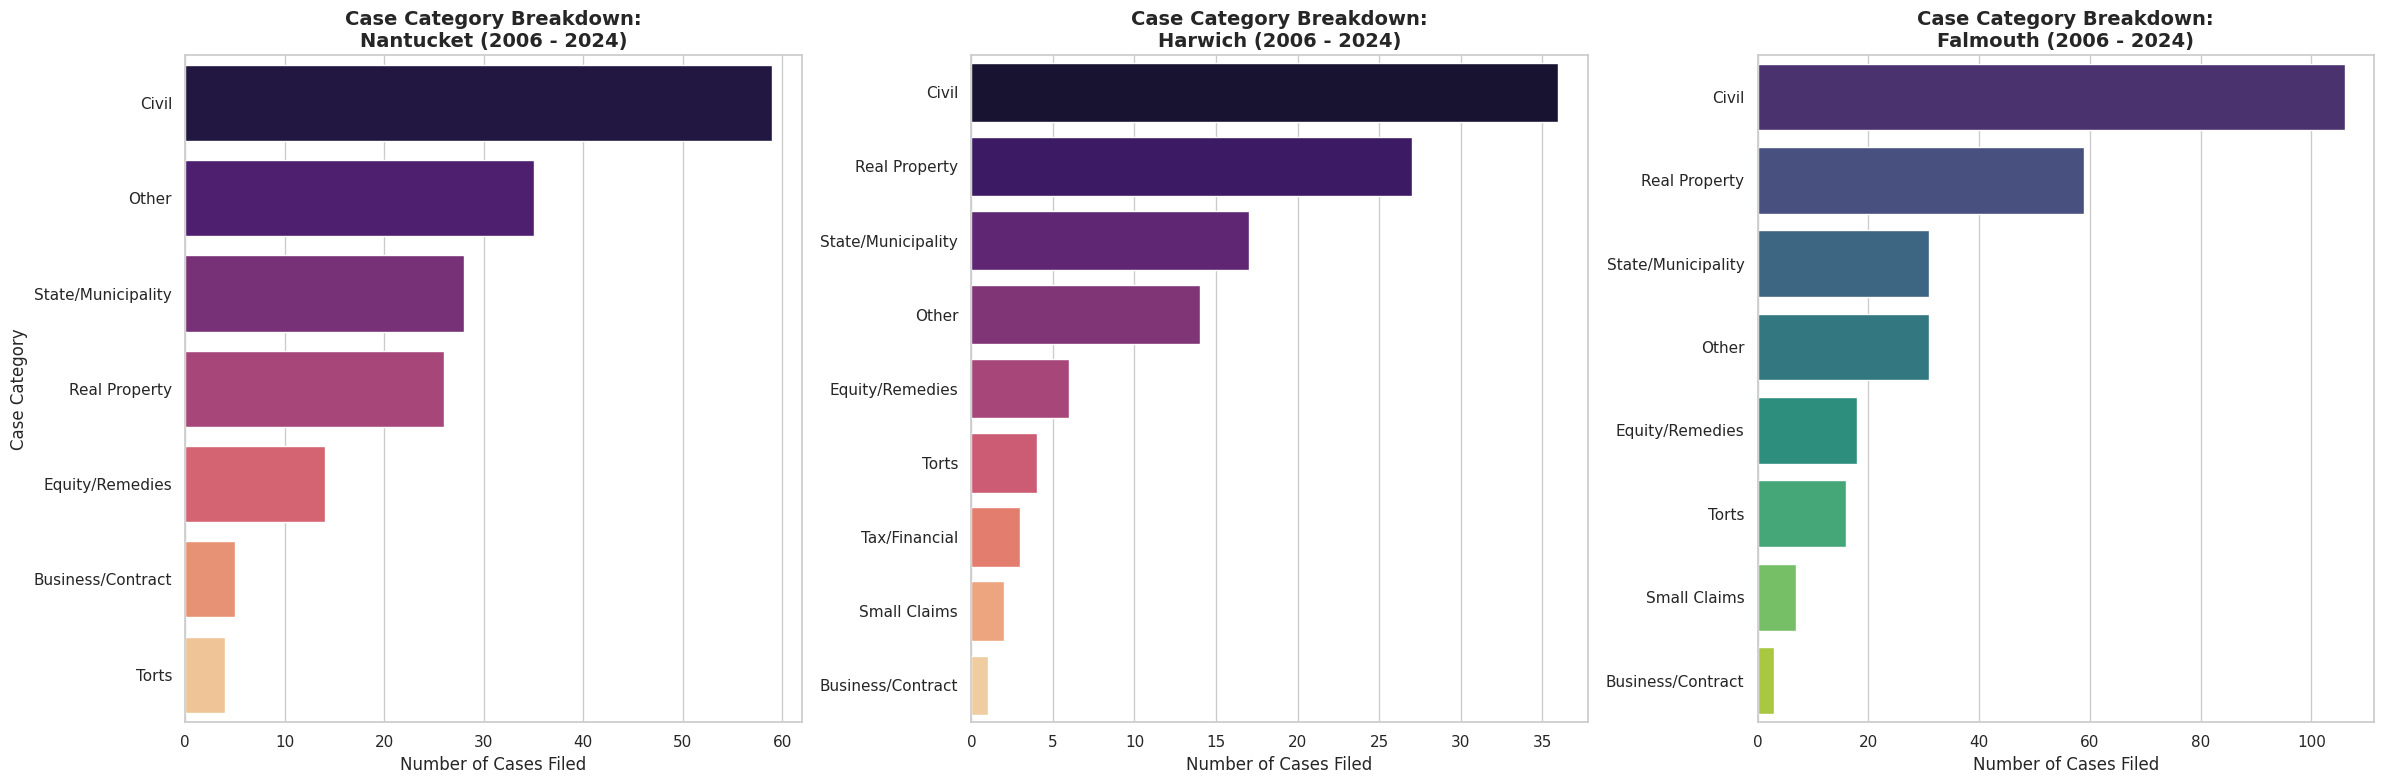

In [ ]:
# --- Category Breakdown for Nantucket, Harwich, and Falmouth ---
import matplotlib.pyplot as plt
import seaborn as sns

# Filter and count categories for Nantucket (#1)
nantucket_cases = municipalCaseParties[municipalCaseParties['municipality'].astype(str).str.lower() == 'nantucket']
nantucket_counts = nantucket_cases['case_category'].value_counts()

# Filter and count categories for Harwich (#2)
harwich_cases = municipalCaseParties[municipalCaseParties['municipality'].astype(str).str.lower() == 'harwich']
harwich_counts = harwich_cases['case_category'].value_counts()

# Filter and count categories for Falmouth (#3)
falmouth_cases = municipalCaseParties[municipalCaseParties['municipality'].astype(str).str.lower() == 'falmouth']
falmouth_counts = falmouth_cases['case_category'].value_counts()

# Set up the plotting environment with 3 subplots side-by-side
fig, axes = plt.subplots(1, 3, figsize=(24, 8), sharex=False)

# Plot 1: Nantucket Breakdown
sns.barplot(
    x=nantucket_counts.values,
    y=nantucket_counts.index,
    hue=nantucket_counts.index,
    palette='magma',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Case Category Breakdown:\nNantucket (2006 - 2024)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Number of Cases Filed', fontsize=12)
axes[0].set_ylabel('Case Category', fontsize=12)

# Plot 2: Harwich Breakdown
sns.barplot(
    x=harwich_counts.values,
    y=harwich_counts.index,
    hue=harwich_counts.index,
    palette='magma',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Case Category Breakdown:\nHarwich (2006 - 2024)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Cases Filed', fontsize=12)
axes[1].set_ylabel('', fontsize=12)

# Plot 3: Falmouth Breakdown
sns.barplot(
    x=falmouth_counts.values,
    y=falmouth_counts.index,
    hue=falmouth_counts.index,
    palette='viridis',
    legend=False,
    ax=axes[2]
)
axes[2].set_title('Case Category Breakdown:\nFalmouth (2006 - 2024)', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Number of Cases Filed', fontsize=12)
axes[2].set_ylabel('', fontsize=12)

plt.tight_layout()
plt.show()